#### In this notebook I will look at the time step in the LSM solver, that is, how large gaps can be in the sampeling.

In [26]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

from camera.camera_file import Camera
from camera.spectralCamera import *
from camera.pdeCamera import *
from camera.lsmCamera import LSM
from solvers.help import *

from waves.waveGenCamera import *

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [27]:
# Wave set-up

L   = 2*2*np.pi
N   = 2**7
dt  = 5e-4
c1 = Camera(L,N,dt)
T = 0.05


amps = np.linspace(0.5,2,4)
means = np.zeros_like(amps)
ps    = L*np.ones_like(amps)

In [28]:
kdvp = KdVPacket(ps, amps, means, c1, T)
H = np.array(kdvp.mainloop())
print(H.shape)

(4, 101, 128)


In [29]:
# lets look at the strides:
max = 20
step = np.arange(2,max+1,2)

In [30]:
h_list = [H]
for stride in step:
    h_list.append(H[:,::stride,:])

In [31]:
x_list = []
lsmlist = []
l_step = np.ones(len(step)+1)
l_step[1:]  =step
for i,h in enumerate(h_list):
    lsm = LSM(eta_list=h, camera=c1, stride=l_step[i])
    x_list.append(lsm.lsm())
    lsmlist.append(lsm)

In [32]:
half = N//2

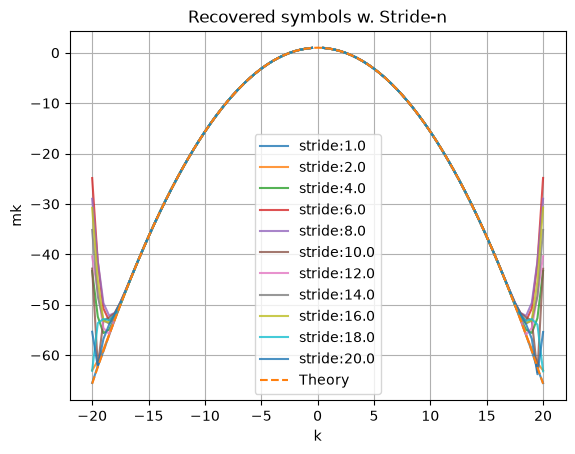

In [56]:
idx = 2*20

order = np.argsort(c1.k)
k = c1.k[order]
# fig, ax = plt.subplots(1,2, figsize = (10,3))

for i,l in enumerate(lsmlist):
    # ell = x_list[i][:,0][order]
    # n   = x_list[i][:,1][order]
    ell = l.ell[order][half-idx:half+idx+1]
    plt.plot(k[half-idx:half+idx+1],ell, label = f"stride:{l_step[i]}", alpha = 0.8 )

plt.plot(k[half-idx:half+idx+1],kdVDispersion(k[half-idx:half+idx+1]), label = "Theory", linestyle = '--')
plt.legend()
plt.grid()

plt.xlabel('k')
plt.ylabel('mk')
plt.title("Recovered symbols w. Stride-n")
plt.show()

From the plot it can look like the stride only affects the solution after it has left the true symbol

C:\Users\henri\AppData\Local\Temp\ipykernel_38604\4109930334.py:17: RuntimeWarning: invalid value encountered in divide
  err_num = np.abs((lsmlist[i].ell[order] - ref_num) / ref_num)


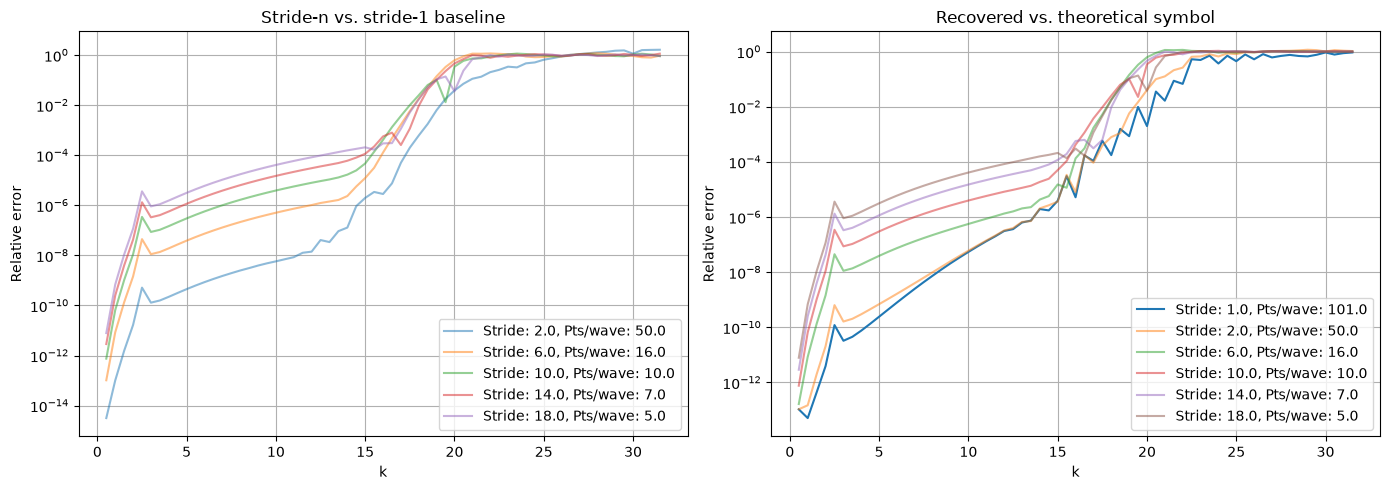

In [62]:
# References
ref_num = lsmlist[0].ell[order]
ref_theory = kdVDispersion(k)

# Create side-by-side subplots
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[1].semilogy(
    k[half:], err_stride1[half:],
    label=f"Stride: {l_step[0]}, Pts/wave: {H.shape[1]//l_step[0]}"
)
for i in range(1, len(lsmlist), 2):

    label = f"Stride: {l_step[i]}, Pts/wave: {H.shape[1]//l_step[i]}"

    # Relative error vs. stride-1 baseline
    err_num = np.abs((lsmlist[i].ell[order] - ref_num) / ref_num)
    ax[0].semilogy(k[half:], err_num[half:], label=label, alpha=0.5)

    # Relative error vs. theoretical symbol
    err_theory = np.abs((lsmlist[i].ell[order] - ref_theory) / ref_theory)
    ax[1].semilogy(k[half:], err_theory[half:], label=label, alpha=0.5)


# Include stride 1 in the theoretical comparison
err_stride1 = np.abs((ref_num - ref_theory) / ref_theory)


# Formatting
ax[0].set_title("Stride-n vs. stride-1 baseline")
ax[1].set_title("Recovered vs. theoretical symbol")

for a in ax:
    a.set_ylabel("Relative error")
    a.set_xlabel("k")
    a.legend(loc="lower right")
    a.grid()

plt.tight_layout()
plt.show()